# Exploración de datos

In [7]:
# Configuración

from pathlib import Path
import matplotlib.pyplot as plt 
import pandas as pd

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = RAIZ / "data" / "raw"
INTERIM = RAIZ / "data" / "interim"

print("pandas", pd.__version__)

pandas 3.0.6


In [8]:
# Para la definición de la "gran tabla" se define una estructura 
# fija: id, fuente, archivo, idioma, uso, texto, y etiqueta

def esquema(df, fuente, archivo, idioma, uso, texto, label, etiquetas):
    nombre = archivo.split("/")[-1].split(".")[0].lower()
    out = pd.DataFrame({
        "id": [f"{fuente}_{nombre}_{i:05d}" for i in range(1, len(df) + 1)],
        "fuente": fuente,
        "archivo": archivo,
        "idioma": idioma,
        "uso": uso,
        "texto": df[texto].astype("string").values,
        "label": df[label].map(etiquetas).values,
    })

    assert out["label"].notna().all(), f"{archivo}: se identificaron etiquetas que no se pudieron traducir"
    return out

In [9]:
# Lectura de conjunto de datos
def leer_dataset(rel):
    ruta = RAW / rel
    return pd.read_excel(ruta) if ruta.suffix == ".xlsx" else pd.read_csv(ruta)

# Dado que que el conjutno Bisaillon no tiene una columna de clasificación, se basa
# de la pertenencia a los archivos

bis_fake = leer_dataset("bisaillon/Fake.csv").assign(etiqueta="Fake")
bis_true = leer_dataset("bisaillon/True.csv").assign(etiqueta = "True")

datasets = [
    esquema(leer_dataset("posadas_duran/train.xlsx"), "posadas_v1", "posadas_duran/train.xlsx", "es", "replica", "Text", "Category", {"Fake": 1, "True": 0}),
    esquema(leer_dataset("posadas_duran/development.xlsx"), "posadas_v1", "posadas_duran/development.xlsx", "es", "replica", "Text", "Category", {"Fake": 1, "True": 0}),
    esquema(leer_dataset("tretiakov/train.csv"), "tretiakov", "tretiakov/train.csv", "es", "replica", "text", "label", {1: 1, 0: 0}),
    esquema(leer_dataset("posadas_duran/test.xlsx"), "posadas_v2", "posadas_duran/test.xlsx", "es", "generalizacion", "TEXT", "CATEGORY", {False: 1, True: 0}),
    esquema(bis_fake, "bisaillon", "bisaillon/Fake.csv", "en", "modelo_b", "text", "etiqueta", {"Fake": 1}),
    esquema(bis_true, "bisaillon", "bisaillon/True.csv", "en", "modelo_b", "text", "etiqueta", {"True": 0}),
    esquema(leer_dataset("ukani/news_datasets.csv"), "ukani", "ukani/news_datasets.csv", "en", "modelo_b", "text", "label", {"FAKE": 1, "REAL": 0}),
]

In [10]:
# Concatenación de noticias
noticias = pd.concat(datasets, ignore_index = True)
noticias["label"] = noticias["label"].astype(int)

assert noticias["id"].is_unique
print(noticias.shape)
noticias.dtypes

(54376, 7)


id            str
fuente        str
archivo       str
idioma        str
uso           str
texto      string
label       int64
dtype: object

### EDA dataset completo

In [12]:
texto = noticias["texto"].fillna("")
noticias["caracteres"] = texto.str.len()
noticias["palabras"] = texto.str.split().str.len()
noticias["vacio"] = texto.str.strip().eq("")
noticias["clave"] = texto.str.lower().str.split().str.join(" ").str[:200]
noticias["tiene_number"] = texto.str.contains("r\*NUMBER\*", regex = True)
noticias["tiene_reuters"] = texto.str[:120].str.contains(r"\(Reuters\)", regex = True)

GRUPOS = ["posadas_v1", "tretiakov", "posadas_v2", "bisaillon", "ukain", "total_es", "total_en", "total"]

def con_totales(df):
    out = pd.concat([
        df.assign(grupo=df["fuente"]),
        df.assign(grupo="total_" + df["idioma"]),
        df.assign(grupo="total")
    ], ignore_index = True)
    out["grupo"] = pd.Categorical(out["grupo"], categories = GRUPOS, ordered = True)
    return out

g = con_totales(noticias)

<>:6: SyntaxWarning: invalid escape sequence '\*'
<>:6: SyntaxWarning: invalid escape sequence '\*'
C:\Users\maria\AppData\Local\Temp\ipykernel_3040\1262929814.py:6: SyntaxWarning: invalid escape sequence '\*'
  noticias["tiene_number"] = texto.str.contains("r\*NUMBER\*", regex = True)
C:\Users\maria\AppData\Local\Temp\ipykernel_3040\1262929814.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  out["grupo"] = pd.Categorical(out["grupo"], categories = GRUPOS, ordered = True)


In [13]:
#Tamaño de archivos y fila

archivos = noticias.groupby(["fuente", "idioma", "archivo"]).size().rename("filas").reset_index()
archivos["MB"] = archivos["archivo"].map(lambda a: (RAW / a).stat().st_size / 1e6)

tamanos = con_totales(archivos).groupby("grupo", observed = True).agg(
    archivos=("archivo", "count"), MB = ("MB", "sum"), filas=("filas", "sum")
)
tamanos["MB"] = tamanos["MB"].round(2)
tamanos["KB por noticia"] = (tamanos["MB"] * 1000 / tamanos["filas"]).round(1)
tamanos 

C:\Users\maria\AppData\Local\Temp\ipykernel_3040\1262929814.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  out["grupo"] = pd.Categorical(out["grupo"], categories = GRUPOS, ordered = True)


,archivos,MB,filas,KB por noticia
grupo,,,,
posadas_v1,2,1.11,971,1.1
tretiakov,1,0.49,1600,0.3
posadas_v2,1,0.92,572,1.6
bisaillon,2,116.37,44898,2.6
total_es,4,2.52,3143,0.8
total_en,3,147.07,51233,2.9
total,7,149.59,54376,2.8


In [15]:
# Filas y balance de clases
balance = g.groupby("grupo", observed = True).agg(filas=("label", "size"), falsas = ("label", "sum"))
balance["reales"] = balance["filas"] - balance["falsas"]
balance["% falsas"] =(100 * balance["falsas"] / balance["filas"]).round(1)
balance["% del total"] = (100 * balance["filas"] / len(noticias)).round(1)
balance

,filas,falsas,reales,% falsas,% del total
grupo,,,,,
posadas_v1,971,480,491,49.4,1.8
tretiakov,1600,800,800,50.0,2.9
posadas_v2,572,286,286,50.0,1.1
bisaillon,44898,23481,21417,52.3,82.6
total_es,3143,1566,1577,49.8,5.8
total_en,51233,26645,24588,52.0,94.2
total,54376,28211,26165,51.9,100.0


In [16]:
# caracteres y palabras
longitud = g.groupby("grupo", observed=True).agg(
    caracteres_mediana=("caracteres", "median"),
    caracteres_promedio=("caracteres", "mean"),
    caracteres_total=("caracteres", "sum"),
    palabras_min=("palabras", "min"),
    palabras_mediana=("palabras", "median"),
    palabras_promedio=("palabras", "mean"),
    palabras_max=("palabras", "max"),
).round(0).astype(int)
longitud["% > 150 palabras"] = (g["palabras"].gt(150).groupby(g["grupo"], observed=True).mean() * 100).round(0)
longitud

,caracteres_mediana,caracteres_promedio,caracteres_total,palabras_min,palabras_mediana,palabras_promedio,palabras_max,% > 150 palabras
grupo,,,,,,,,
posadas_v1,1896,2355,2286588,20,315,390,2566,92.0
tretiakov,255,235,376552,6,42,40,379,0.0
posadas_v2,2422,3184,1821165,47,398,521,4006,90.0
bisaillon,2186,2469,110858087,0,362,405,8135,80.0
total_es,255,1427,4484305,6,50,236,4006,45.0
total_en,2261,2746,140678518,0,374,451,20891,81.0
total,2207,2670,145162823,0,365,439,20891,79.0


In [17]:
# Mediana de palabras por clase: ¿la longitud delata la etiqueta?
pd.crosstab(g["grupo"], g["label"].map({0: "real", 1: "falsa"}), values=g["palabras"], aggfunc="median")

label,falsa,real
grupo,,
posadas_v1,274.5,383.0
tretiakov,42.5,42.0
posadas_v2,301.0,545.0
bisaillon,363.0,359.0
total_es,50.0,50.0
total_en,367.0,384.0
total,359.0,376.0


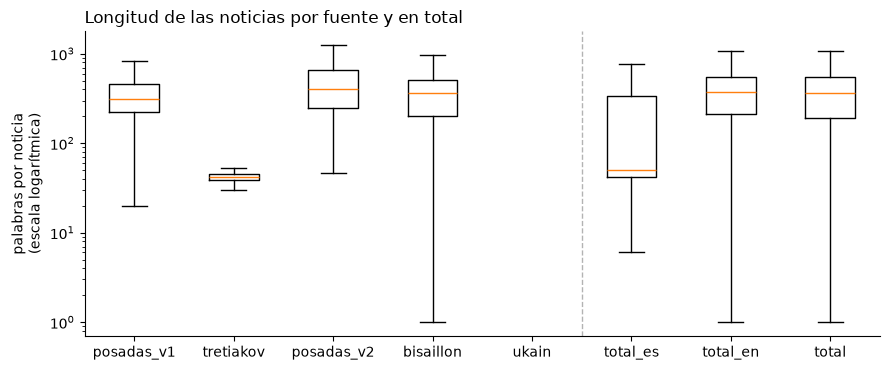

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot([g.loc[g["grupo"] == x, "palabras"].clip(lower=1) for x in GRUPOS], showfliers=False, widths=0.5)
ax.set_xticks(range(1, len(GRUPOS) + 1), GRUPOS)
ax.axvline(5.5, color="0.7", lw=1, ls="--")   # separa las fuentes de los totales
ax.set_yscale("log")
ax.set_ylabel("palabras por noticia\n(escala logarítmica)")
ax.set_title("Longitud de las noticias por fuente y en total", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Calidad de los datos

In [19]:
def duplicados(df):
    return df.loc[~df["vacio"], "clave"].duplicated().sum()

por_grupo = g.groupby("grupo", observed=True)
calidad = pd.DataFrame({
    "vacíos": por_grupo["vacio"].sum(),
    "duplicados": por_grupo[["vacio", "clave"]].apply(duplicados),
    "con *NUMBER*": por_grupo["tiene_number"].sum(),
    "con (Reuters) al inicio": por_grupo["tiene_reuters"].sum(),
})
calidad["% duplicados"] = (100 * calidad["duplicados"] / balance["filas"]).round(1)
calidad

,vacíos,duplicados,con *NUMBER*,con (Reuters) al inicio,% duplicados
grupo,,,,,
posadas_v1,0,6,0,0,0.6
tretiakov,0,44,0,0,2.8
posadas_v2,0,0,0,0,0.0
bisaillon,631,6008,0,21145,13.4
total_es,0,66,0,0,2.1
total_en,667,6272,0,21155,12.2
total,667,6338,0,21155,11.7


In [22]:
# Duplicados ENTRE fuentes: el mismo texto en dos datasets distintos
validos = noticias[~noticias["vacio"]]
entre = validos.groupby("clave").filter(lambda d: d["fuente"].nunique() > 1)
print("Textos que aparecen en más de una fuente:", entre["clave"].nunique())
display(entre.groupby(["fuente", "label"]).size().rename("noticias"))

# Tretiakov viene recortado, así que además se busca su comienzo DENTRO de los textos de Posadas
inicio_tret = noticias.loc[noticias["fuente"] == "tretiakov", "texto"].str.strip().str[:80]
for f in ["posadas_v1", "posadas_v2"]:
    todo = "\n".join(noticias.loc[noticias["fuente"] == f, "texto"].fillna(""))
    print(f"Tretiakov dentro de {f}:", inicio_tret.apply(lambda s: s in todo).sum())

Textos que aparecen en más de una fuente: 16


fuente      label
posadas_v2  1        16
tretiakov   1        21
Name: noticias, dtype: int64

Tretiakov dentro de posadas_v1: 4
Tretiakov dentro de posadas_v2: 24


In [23]:
replica = noticias[noticias["uso"] == "replica"]
print("Noticias para la réplica:", len(replica), "| falsas:", replica["label"].sum(), "| reales:", (replica["label"] == 0).sum())
print("Del artículo:            2571 | falsas: 1280 | reales: 1291")

Noticias para la réplica: 2571 | falsas: 1280 | reales: 1291
Del artículo:            2571 | falsas: 1280 | reales: 1291


In [25]:
# Guardar datos
INTERIM.mkdir(parents=True, exist_ok=True)
salida = INTERIM / "noticias_unidas.csv"
noticias[["id", "fuente", "archivo", "idioma", "uso", "texto", "label"]].to_csv(salida, index=False, encoding="utf-8")

print(f"Guardado: {salida.relative_to(RAIZ)} ({salida.stat().st_size / 1e6:.1f} MB)")
print(pd.read_csv(salida).shape)

Guardado: data\interim\noticias_unidas.csv (149.8 MB)
(54376, 7)
